In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%pip install openpyxl
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


ModuleNotFoundError: No module named 'openpyxl'

In [ ]:

df=pd.read_excel("mall_customer_spend.xlsx")


In [ ]:
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [ ]:
df.shape


(200, 5)

In [ ]:
df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
df.isnull().sum()


CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [ ]:
df['Genre'].unique()


<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [ ]:
df['Spending Score (1-100)'].unique()


array([39, 81,  6, 77, 40, 76, 94,  3, 72, 14, 99, 15, 13, 79, 35, 66, 29,
       98, 73,  5, 82, 32, 61, 31, 87,  4, 92, 17, 26, 75, 36, 28, 65, 55,
       47, 42, 52, 60, 54, 45, 41, 50, 46, 51, 56, 59, 48, 49, 53, 44, 57,
       58, 43, 91, 95, 11,  9, 34, 71, 88,  7, 10, 93, 12, 97, 74, 22, 90,
       20, 16, 89,  1, 78, 83, 27, 63, 86, 69, 24, 68, 85, 23,  8, 18])

In [ ]:
df['Annual Income (k$)'].unique()


array([ 15,  16,  17,  18,  19,  20,  21,  23,  24,  25,  28,  29,  30,
        33,  34,  37,  38,  39,  40,  42,  43,  44,  46,  47,  48,  49,
        50,  54,  57,  58,  59,  60,  61,  62,  63,  64,  65,  67,  69,
        70,  71,  72,  73,  74,  75,  76,  77,  78,  79,  81,  85,  86,
        87,  88,  93,  97,  98,  99, 101, 103, 113, 120, 126, 137])

In [ ]:
df['Age'].unique()


array([19, 21, 20, 23, 31, 22, 35, 64, 30, 67, 58, 24, 37, 52, 25, 46, 54,
       29, 45, 40, 60, 53, 18, 49, 42, 36, 65, 48, 50, 27, 33, 59, 47, 51,
       69, 70, 63, 43, 68, 32, 26, 57, 38, 55, 34, 66, 39, 44, 28, 56, 41])

In [ ]:
df['Genre']= df['Genre'].map({'Female':0,'Male':1})


In [ ]:
df['Genre']


0      1
1      1
2      0
3      0
4      0
      ..
195    0
196    0
197    1
198    1
199    1
Name: Genre, Length: 200, dtype: int64

In [ ]:
#Selecting relevant features for clustering
X=df[['Annual Income (k$)','Spending Score (1-100)']]


In [ ]:
#Scale numeric features appropriately
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)


In [ ]:
#demonstration of random initialization trap

kmeans1 = KMeans(
    n_clusters=5,
    init='random',
    n_init=1,
    random_state=1
)

kmeans2 = KMeans(
    n_clusters=5,
    init='random',
    n_init=1,
    random_state=20
)

cluster1 = kmeans1.fit_predict(X_scaled)
cluster2 = kmeans2.fit_predict(X_scaled)

print(kmeans1.inertia_)
print(kmeans2.inertia_)


65.56840815571681
98.76359704464724


Different random initializations can produce different clustering results. To overcome the Random Initialization Trap, the final K-Means model uses random_state=42 for reproducibility and n_init=10 to run the algorithm multiple times and select the solution with the lowest inertia.

In [ ]:
#calculating inertia to use in elbow method.

inertia=[]
for k in range(1,11):
    model=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)
    print(k,model.inertia_)


1 400.0
2 269.69101219276394
3 157.70400815035947
4 108.92131661364357
5 65.56840815571681
6 55.057348270386
7 44.86475569922557
8 37.228187677585886
9 32.392267630331176
10 29.981897788243693


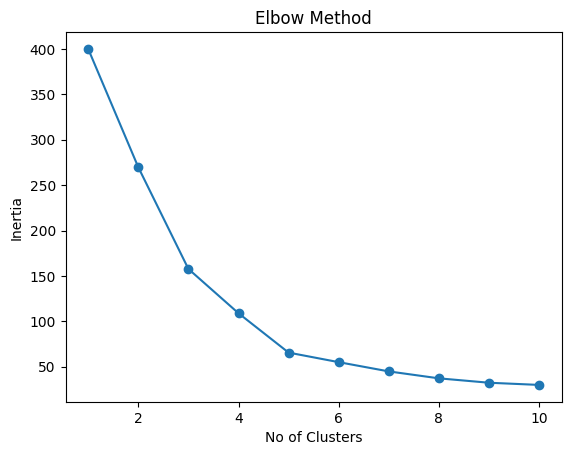

In [ ]:
plt.plot(range(1,11),inertia,marker='o')
plt.title("Elbow Method")
plt.xlabel("No of Clusters")
plt.ylabel("Inertia")
plt.show()


The elbow point is observed at K = 5, where the decrease in inertia begins to level off. Therefore, five clusters were selected for the final K-Means model.

In [ ]:
kmeans=KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters=kmeans.fit_predict(X_scaled)
df['Clusters'] = clusters

print("Final model inertia:",kmeans.inertia_) #the best inertia value is 65.56 and the corresponding cluster value is 5


Final model inertia: 65.56840815571681


In [ ]:
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Clusters
0,1,1,19,15,39,4
1,2,1,21,15,81,2
2,3,0,20,16,6,4
3,4,0,23,16,77,2
4,5,0,31,17,40,4


In [ ]:
df['Clusters'].value_counts()#no of data points in each clusters


Clusters
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64

In [ ]:
#finding the centroids

centroids=kmeans.cluster_centers_
centroids


array([[-0.20091257, -0.02645617],
       [ 0.99158305,  1.23950275],
       [-1.32954532,  1.13217788],
       [ 1.05500302, -1.28443907],
       [-1.30751869, -1.13696536]])

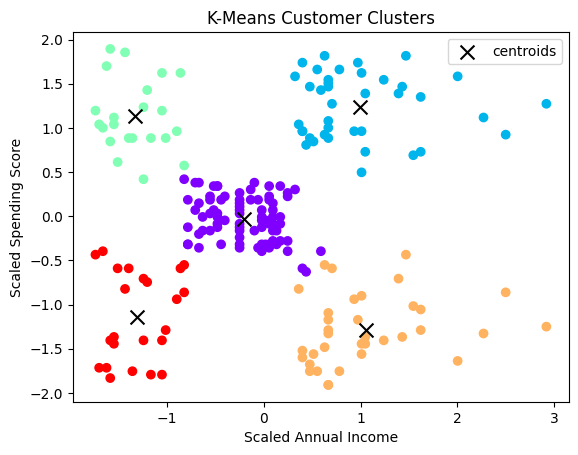

In [ ]:
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=clusters,
    cmap='rainbow'
)

plt.scatter(centroids[:,0],centroids[:,1],marker='x',c='black',s=100,label='centroids')
plt.title('K-Means Customer Clusters')
plt.xlabel('Scaled Annual Income')
plt.ylabel('Scaled Spending Score')
plt.legend()
plt.show()


The K-Means algorithm partitioned the customers into five distinct clusters based on Annual Income and Spending Score. 

The centroids represent the average position of customers in each cluster. 

The clusters are compact and clearly separated, making customer segmentation easy to interpret.

In [ ]:
#Dendogram
from scipy.cluster.hierarchy import dendrogram,linkage


In [ ]:
linked = linkage(X_scaled,method='ward')


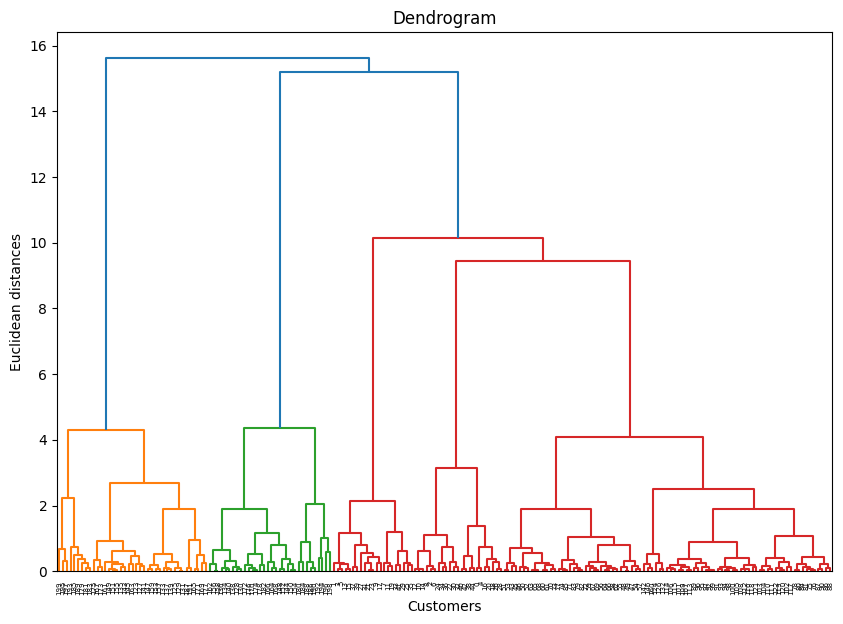

In [ ]:
plt.figure(figsize=(10,7))
dendrogram(linked)
plt.title("Dendrogram")
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()


In [ ]:
from sklearn.cluster import AgglomerativeClustering


In [ ]:
hc=AgglomerativeClustering(n_clusters=5,linkage='ward')
#As per the dendogram, a horizontal line from euclidean distance 7 in y-axis will cut through 5 vertical lines. So im selecting cluster = 5


In [ ]:
y_pred = hc.fit_predict(X_scaled)


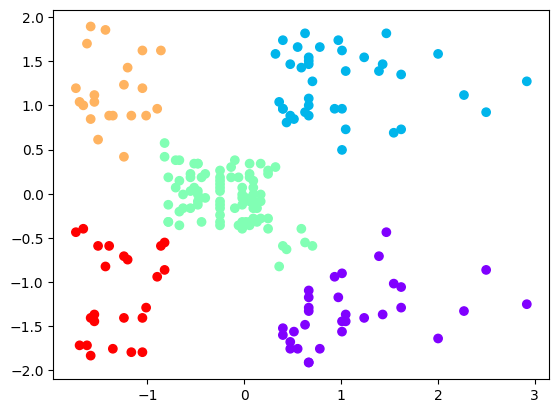

In [ ]:
plt.scatter(
    X_scaled[:,0], 
    X_scaled[:,1], 
    c=y_pred,
    cmap = "rainbow"
)
plt.show()


In [ ]:
df['hc_clusters']=y_pred
df['hc_clusters'].value_counts().sort_index()


hc_clusters
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

Agglomerative Hierarchical Clustering also identified five customer groups similar to those obtained using K-Means. The cluster boundaries differ slightly because the algorithm follows a bottom-up merging approach rather than centroid optimization.

In [ ]:
#DB Scan
from sklearn.cluster import DBSCAN


In [ ]:

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

db_clusters = dbscan.fit_predict(X_scaled)

df['DBSCAN_Cluster'] = db_clusters


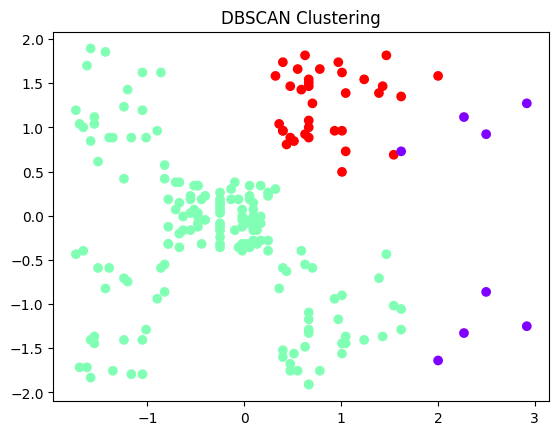

In [ ]:
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=db_clusters,
    cmap='rainbow'
)

plt.title("DBSCAN Clustering")

plt.show()


In [ ]:
# Number of customers in each cluster
print(df['DBSCAN_Cluster'].value_counts().sort_index())

# Number of noise points
print("Noise points:", (df['DBSCAN_Cluster'] == -1).sum())


DBSCAN_Cluster
-1      8
 0    157
 1     35
Name: count, dtype: int64
Noise points: 8


The DB scan algorithmn has used 3 clusters. -1 indicates outliers and there are 8 outliers. 

Comparison of Clustering Algorithms


Algorithm	Observation

K-Means	Produced five compact customer segments and was easy to interpret.

Hierarchical Clustering	Also identified five similar clusters. The dendrogram helped determine the appropriate number of clusters.

DBSCAN	Identified three dense clusters and detected eight noise points (outliers). Unlike K-Means, it does not require specifying the number of clusters beforehand.

In [ ]:
#PCA 
from sklearn.decomposition import PCA


In [ ]:
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Clusters,hc_clusters,DBSCAN_Cluster
0,1,1,19,15,39,4,4,0
1,2,1,21,15,81,2,3,0
2,3,0,20,16,6,4,4,0
3,4,0,23,16,77,2,3,0
4,5,0,31,17,40,4,4,0


In [ ]:
df_new=df[['Age','Genre','Annual Income (k$)','Spending Score (1-100)']]


In [ ]:
x_scaled_PCA=scaler.fit_transform(df_new)


In [ ]:
pca=PCA(n_components=2)


In [ ]:
X_PCA=pca.fit_transform(x_scaled_PCA)


In [ ]:
print(X_PCA.shape)


(200, 2)


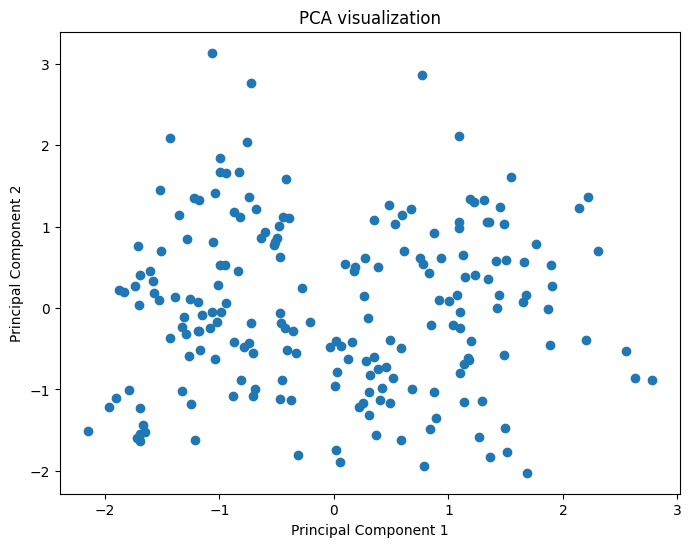

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_PCA[:,0],
    X_PCA[:,1]
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA visualization")

plt.show()


In [ ]:
print(pca.explained_variance_ratio_)


[0.33690046 0.26230645]


In [ ]:
print("PCA Variance")
print(sum(pca.explained_variance_ratio_))


PCA Variance
0.5992069019819847


In [ ]:
#Tsne

from sklearn.manifold import TSNE


In [ ]:

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(x_scaled_PCA)


In [ ]:
x_scaled_PCA.shape


(200, 4)

In [ ]:
X_tsne.shape


(200, 2)

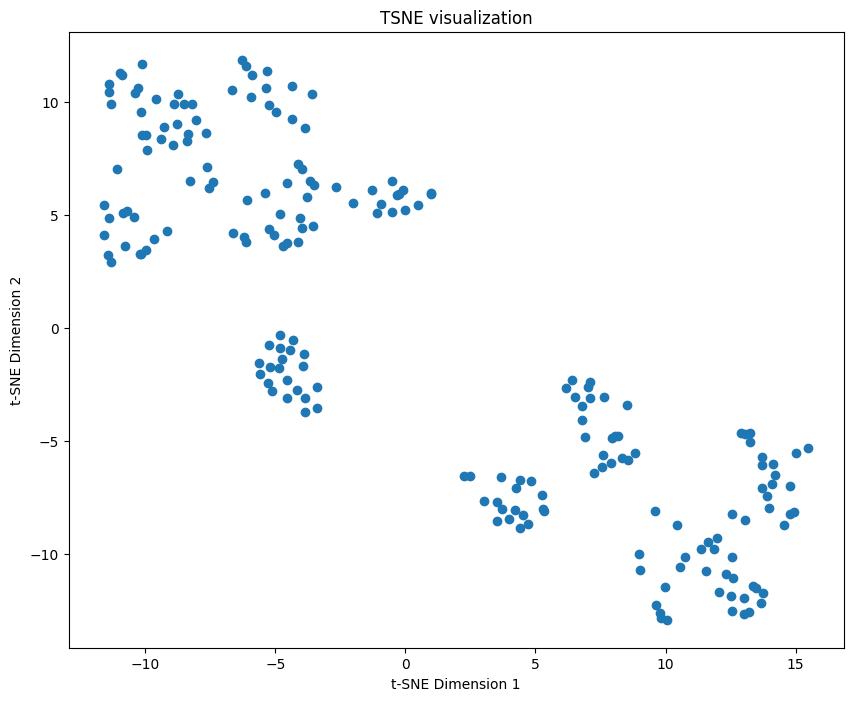

In [ ]:
plt.figure(figsize=(10, 8))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1])
plt.title("TSNE visualization")
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.show()


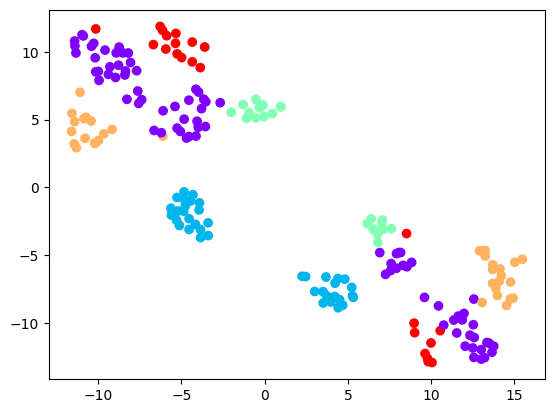

In [ ]:
#using clusters from k_means for coloring
plt.scatter(
    X_tsne[:,0],
    X_tsne[:,1],
    c=clusters,      # K-Means labels
    cmap='rainbow'
)


Comparison of PCA and t-SNE

PCA reduced the data into two principal components while preserving the maximum variance in the dataset.

t-SNE produced a clearer visualization by preserving local relationships between similar customers, making the customer groups more distinguishable.

PCA is mainly used for dimensionality reduction and feature extraction, whereas t-SNE is primarily used for visualization.

In this dataset, t-SNE provided better visual separation of customer groups compared to PCA.

In [ ]:
#cluster analysis using Kmeans algorithm result

cluster_analysis = df.groupby('Clusters').agg({
    'Age':'mean',
    'Annual Income (k$)':'mean',
    'Spending Score (1-100)':'mean'
}).round(2)

print(cluster_analysis)


            Age  Annual Income (k$)  Spending Score (1-100)
Clusters                                                   
0         42.72               55.30                   49.52
1         32.69               86.54                   82.13
2         25.27               25.73                   79.36
3         41.11               88.20                   17.11
4         45.22               26.30                   20.91


Cluster Analysis (K-Means)

Based on the average values of Age, Annual Income, and Spending Score, five distinct customer segments were identified.

Cluster	Characteristics	Customer Segment


Cluster 0	Medium income (55.30k$), medium spending score (49.52), average age (42.72)	Average Customers

Cluster 1	High income (86.54k$), highest spending score (82.13), relatively young (32.69 years)	High-Value Customers

Cluster 2	Low income (25.73k$), high spending score (79.36), youngest customers (25.27 years)	Enthusiastic Shoppers

Cluster 3	High income (88.20k$), lowest spending score (17.11), middle-aged (41.11 years)	Wealthy but Low-Spending Customers

Cluster 4	Low income (26.30k$), low spending score (20.91), oldest customers (45.22 years)	Budget-Conscious Customers

Business Insights

Cluster 0 – Average Customers

These customers have moderate income and moderate spending habits.

They represent a stable customer base with potential for increased purchases.

Recommendation: Introduce loyalty programs, seasonal offers, and cross-selling strategies to encourage higher spending.

Cluster 1 – High-Value Customers

These customers have both high annual income and the highest spending score, making them the most profitable customer segment.

They are likely to purchase premium and luxury products.

Recommendation: Offer VIP memberships, personalized recommendations, exclusive product launches, premium services, and reward programs to improve customer retention.

Cluster 2 – Enthusiastic Shoppers

These customers have low income but high spending behavior, indicating strong interest in shopping despite limited purchasing power.

They are also the youngest customer group.

Recommendation: Target them with discounts, cashback offers, student or youth promotions, and affordable product bundles to maintain engagement and encourage repeat purchases.

Cluster 3 – Wealthy but Low-Spending Customers

These customers have high income but very low spending, suggesting untapped business potential.

They may not be fully engaged with the mall's products or services.

Recommendation: Use personalized marketing campaigns, premium product demonstrations, exclusive events, and targeted promotions to increase their purchasing activity.

Cluster 4 – Budget-Conscious Customers

These customers have low income and low spending, making them highly price-sensitive.

They are less likely to purchase premium products.

Recommendation: Focus on discounts, value-for-money products, coupons, and promotional campaigns to improve their shopping frequency.

Overall Business Recommendations
Retain high-value customers (Cluster 1) through premium services, loyalty rewards, and exclusive shopping experiences.

Increase engagement of wealthy but low-spending customers (Cluster 3) using personalized marketing and targeted promotions.

Encourage repeat purchases among enthusiastic shoppers (Cluster 2) with affordable offers, cashback, and reward points.

Strengthen loyalty among average customers (Cluster 0) through cross-selling and membership benefits.

Attract budget-conscious customers (Cluster 4) by offering discounts, festive sales, and economical product bundles.

The K-Means algorithm successfully segmented customers into five meaningful groups based on their income and spending behavior. These segments enable the retail mall to implement targeted marketing strategies, improve customer satisfaction, increase customer retention, and optimize overall business profitability.